## FLIP2 RHODOPSIN: Simple Baselines

In [14]:
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, pearsonr
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

DATA_PATH = "by_wild_type.csv.gz"
SEED = 0

In [15]:
#same split decoding as the explore nb

df = pd.read_csv(DATA_PATH, compression="gzip")
df["validation"] = df["validation"].astype(str).str.lower().eq("true")
df["split"] = np.where(df["validation"], "val", df["set"])

#all duplicates sit inside a single split (exact overlap across splits was 0), so grouping by (split, sequence) is safe
n_before = len(df)
df = df.groupby(["split", "sequence"], as_index=False)["target"].mean()
print(f"Rows: {n_before} -> {len(df)} after dedup")
print(df["split"].value_counts())


Rows: 884 -> 878 after dedup
split
train    578
test     184
val      116
Name: count, dtype: int64


In [16]:
train = df[df["split"] == "train"].reset_index(drop=True)
val   = df[df["split"] == "val"].reset_index(drop=True)
test  = df[df["split"] == "test"].reset_index(drop=True)

y_tr, y_va, y_te = train["target"].values, val["target"].values, test["target"].values

# Unified Evaluation Function
- Utilizes MAE over nm
- Spearman p: determines rank quality, what FLIP2 reports. Used for screening candidates
- Note: Constant predictors (mean for exmaple) will have NaN as its value

In [17]:
def evaluate(y_true, y_pred):
    const = np.allclose(y_pred, y_pred[0])
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "Spearman": np.nan if const else spearmanr(y_true, y_pred).statistic,
        "Pearson": np.nan if const else pearsonr(y_true, y_pred).statistic,
    }

results = {}  # model name -> {"val": ..., "test": ..., "pred_test": ...}

def record(name, pred_va, pred_te):
    results[name] = {"val": evaluate(y_va, pred_va), "test": evaluate(y_te, pred_te), "pred_test": pred_te}

# B0 Train Mean

In [18]:
mean = y_tr.mean()

record("BO train mean", np.full(len(val), mean), np.full(len(test), mean))
print(f"Train mean: {mean:.1f} nm")

Train mean: 539.9 nm


# B1 Nearest Train Sequence

- Sequences become 3-mer count vectors, cosine similarity then finds the closest training seuqnces, ultimately, this baseline can only say "it looks like something ive seen".

In [19]:
kmer = CountVectorizer(analyzer="char", ngram_range=(3, 3), lowercase=False)
K_tr = kmer.fit_transform(train["sequence"])
K_va = kmer.transform(val["sequence"])
K_te = kmer.transform(test["sequence"])

knn_scores = {}
for k in [1, 3, 5, 10, 20]:
    knn = KNeighborsRegressor(n_neighbors=k, metric="cosine", weights="distance").fit(K_tr, y_tr)
    knn_scores[k] = mean_absolute_error(y_va, knn.predict(K_va))
best_k = min(knn_scores, key=knn_scores.get)
print("Val MAE by k:", {k: round(v, 2) for k, v in knn_scores.items()}, "-> best k =", best_k)

knn = KNeighborsRegressor(n_neighbors=best_k, metric="cosine", weights="distance").fit(K_tr, y_tr)
record(f"B1 kNN 3-mer (k={best_k})", knn.predict(K_va), knn.predict(K_te))

Val MAE by k: {1: 31.03, 3: 29.82, 5: 26.36, 10: 25.88, 20: 27.68} -> best k = 10


# Composition Features

AAC: fraciton of ecah of the 20 amino acids
DPC: fraction of each of the 400 adjacent amino acid pairs

In [20]:
AA = "ACDEFGHIKLMNPQRSTVWY"
DIPEPTIDES = ["".join(p) for p in product(AA, repeat=2)]

def aac(seq):
    counts = np.array([seq.count(a) for a in AA], dtype=float)
    return counts / max(len(seq), 1)

def dpc(seq):
    idx = {d: i for i, d in enumerate(DIPEPTIDES)}
    v = np.zeros(len(DIPEPTIDES))
    for i in range(len(seq) - 1):
        j = idx.get(seq[i:i + 2])
        if j is not None:
            v[j] += 1
    return v / max(len(seq) - 1, 1)

def featurize(frame, fn):
    return np.vstack([fn(s) for s in frame["sequence"]])

X = {name: (featurize(train, fn), featurize(val, fn), featurize(test, fn))
     for name, fn in [("AAC", aac), ("DPC", dpc)]}
print({k: v[0].shape for k, v in X.items()})

{'AAC': (578, 20), 'DPC': (578, 400)}


#B2 amd B3: Ridge REgression

Alpha is swept on val, heavy regularization version is expected to win out here

In [21]:
ALPHAS = np.logspace(-2, 4, 13)

def fit_ridge(X_tr, X_va, X_te, label):
    val_mae = {}
    for a in ALPHAS:
        m = make_pipeline(StandardScaler(), Ridge(alpha=a)).fit(X_tr, y_tr)
        val_mae[a] = mean_absolute_error(y_va, m.predict(X_va))
    best_a = min(val_mae, key=val_mae.get)
    m = make_pipeline(StandardScaler(), Ridge(alpha=best_a)).fit(X_tr, y_tr)
    print(f"{label}: best alpha = {best_a:.3g}, val MAE = {val_mae[best_a]:.2f}")
    record(f"{label} (α={best_a:.2g})", m.predict(X_va), m.predict(X_te))
    return m

ridge_aac = fit_ridge(*X["AAC"], "B2 ridge AAC")
ridge_dpc = fit_ridge(*X["DPC"], "B3 ridge DPC")

B2 ridge AAC: best alpha = 1e+04, val MAE = 21.70
B3 ridge DPC: best alpha = 1e+04, val MAE = 22.31


# Unified Eval

In [22]:
rows = []
for name, r in results.items():
    rows.append({"model": name,
                 **{f"val_{k}": v for k, v in r["val"].items()},
                 **{f"test_{k}": v for k, v in r["test"].items()}})
summary = pd.DataFrame(rows).set_index("model").round(3)
summary[["val_MAE", "val_Spearman", "test_MAE", "test_RMSE", "test_Spearman", "test_Pearson"]]

,val_MAE,val_Spearman,test_MAE,test_RMSE,test_Spearman,test_Pearson
model,,,,,,
BO train mean,21.361,NaN,24.603,32.532,NaN,NaN
B1 kNN 3-mer (k=10),25.877,-0.020,28.592,37.371,-0.164,-0.094
B2 ridge AAC (α=1e+04),21.697,0.024,23.142,30.834,0.320,0.395
B3 ridge DPC (α=1e+04),22.314,-0.311,24.962,34.289,0.071,-0.076


# Eval on Test

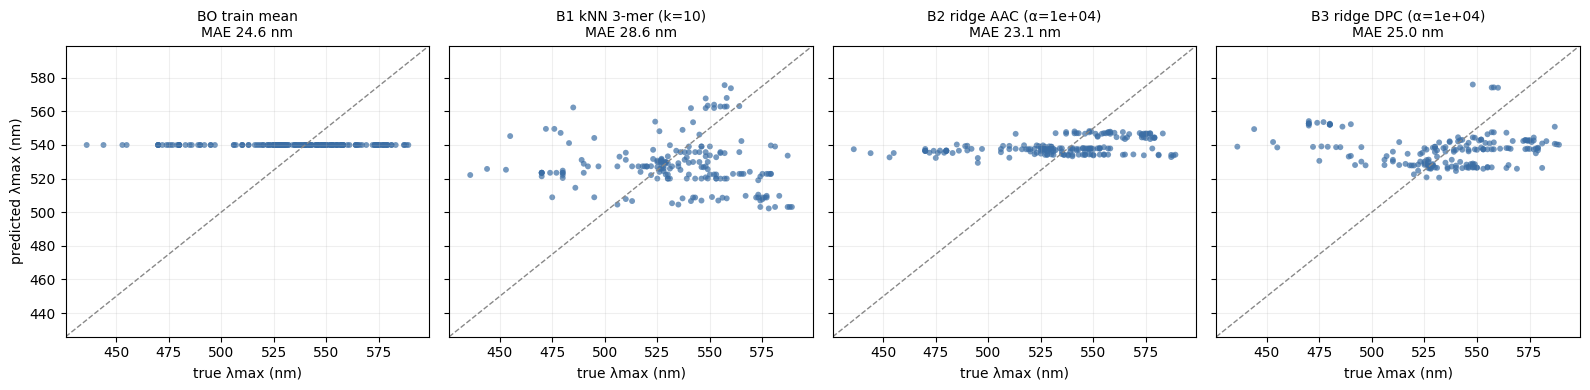

In [23]:
names = list(results)
fig, axes = plt.subplots(1, len(names), figsize=(4 * len(names), 4), sharex=True, sharey=True)
lo, hi = y_te.min() - 10, y_te.max() + 10
for ax, name in zip(axes, names):
    p = results[name]["pred_test"]
    ax.plot([lo, hi], [lo, hi], ls="--", lw=1, color="#888888")
    ax.scatter(y_te, p, s=18, alpha=0.7, color="#3b6ea5", edgecolors="none")
    m = results[name]["test"]
    ax.set_title(f"{name}\nMAE {m['MAE']:.1f} nm", fontsize=10)
    ax.set_xlabel("true λmax (nm)")
    ax.grid(alpha=0.2)
axes[0].set_ylabel("predicted λmax (nm)")
for ax in axes:
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
plt.tight_layout()
plt.show()

# Findings:

No baseline is able to learn color rules that transfer to unseen rhodopsin 

1. Nothing handily beats the mean, most of them are close to it so what its telling me right now is that the features right now carry almost no signal

2. The Family shortcut is actually worse than knowing nothing. kNN (B1) gets 28.6 nm MAE, worse than literally just predicting the mean over and over. Test proteins that are truly 575 to 590 get predicted much lower. B3 does the same thing in reverse

    - This implies that global sequence similarity is unable to repdict color within the dataset, proteins can look alike but absorb different colors.
3. Composition features average the signal away. The composition features summarize all 250 to 300 residues, so the few pocket residues that get color get dilluted to nothing.